# Handwritten digit recognition with a neural network (MNIST)

A multi-layer perceptron built with scikit-learn recognises handwritten digits 0 to 9.

The steps are:
1. load MNIST and split it;
2. normalise the pixels to 0 to 1;
3. build and train the network;
4. evaluate the test accuracy and loss.

The data is downloaded once from OpenML (`mnist_784`, about 15 MB) and cached in `~/scikit_learn_data`. Figures are written to `figures/` and the scores to `results.json`.

In [1]:
import json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss, classification_report, confusion_matrix, ConfusionMatrixDisplay
import sklearn
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## Step 1. Load the MNIST dataset and split it

70,000 greyscale images of handwritten digits, each 28 × 28 pixels. The standard split is used: the first 60,000 images for training and the last 10,000 for testing.

In [2]:
mnist = fetch_openml("mnist_784", version=1, as_frame=False, parser="liac-arff")
X, y = mnist.data, mnist.target.astype(int)
print("images:", X.shape, "labels:", y.shape, "pixel range:", X.min(), "to", X.max())
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]
print("train", X_train.shape, "test", X_test.shape)
print("digits in training set:", np.bincount(y_train))

images: (70000, 784) labels: (70000,) pixel range: 0.0 to 255.0
train (60000, 784) test (10000, 784)
digits in training set: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


**A look at the data.** Each row of 784 numbers is reshaped back to a 28 × 28 picture.

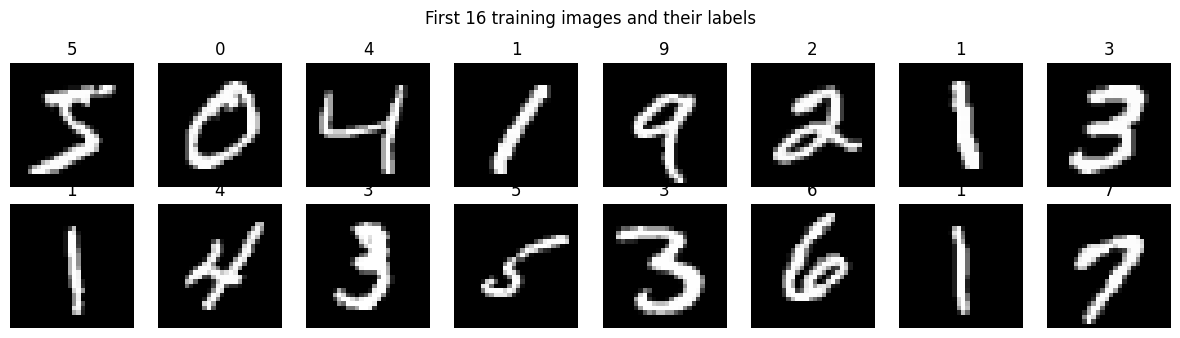

In [3]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, lab in zip(axes.ravel(), X_train[:16], y_train[:16]):
    ax.imshow(img.reshape(28, 28), cmap="gray"); ax.set_title(str(lab)); ax.axis("off")
plt.suptitle("First 16 training images and their labels")
plt.tight_layout(); plt.savefig(FIG / "samples.png", dpi=150); plt.show()

## Step 2. Preprocess the data

- **Normalise:** pixel values run from 0 (black) to 255 (white). Dividing by 255 puts them in the range 0 to 1, which helps the network train faster and more steadily.
- **Reshape:** an MLP takes a flat list of inputs, so each 28 × 28 image is kept as a vector of 784 values. (A CNN would keep the 28 × 28 shape.)

In [4]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
print("after scaling:", X_train.min(), "to", X_train.max(), "| input vector length:", X_train.shape[1])

after scaling: 0.0 to 1.0 | input vector length: 784


## Step 3. Build and train the network

**Architecture:** 784 inputs → 128 ReLU neurons → 64 ReLU neurons → 10 softmax outputs (one per digit).

- **Optimiser:** Adam, learning rate 0.001, batches of 128 images.
- **Early stopping:** 10% of the training images are held back for validation. Training stops when the validation score has not improved for 5 epochs, which guards against overfitting.

In [5]:
mlp = MLPClassifier(hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
                    learning_rate_init=0.001, batch_size=128, max_iter=50,
                    early_stopping=True, validation_fraction=0.1, n_iter_no_change=5,
                    random_state=42)
t0 = time.time()
mlp.fit(X_train, y_train)
train_time = time.time() - t0
n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
print(f"epochs run: {mlp.n_iter_}   training time: {train_time:.0f} s   parameters: {n_params:,}")
print("best validation accuracy: %.4f" % mlp.best_validation_score_)

epochs run: 20   training time: 4 s   parameters: 109,386
best validation accuracy: 0.9782


**Training curves.** The training loss should fall each epoch and the validation accuracy should rise and then level off.

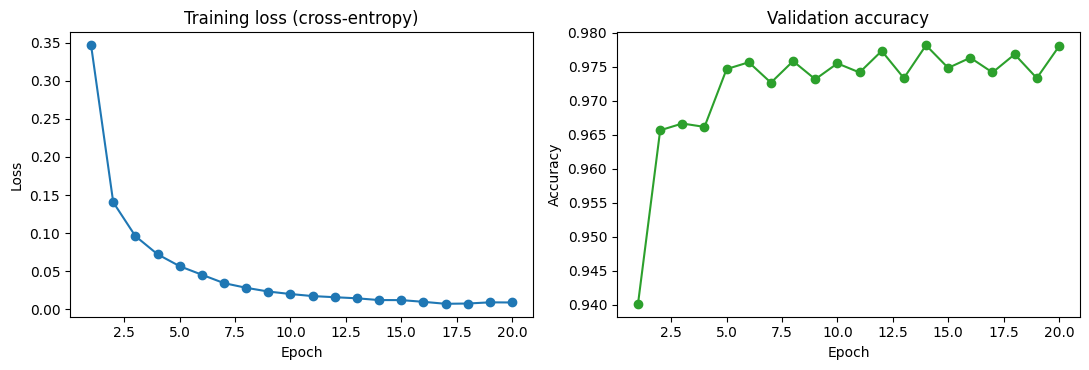

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, marker="o")
axes[0].set_title("Training loss (cross-entropy)"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[1].plot(range(1, len(mlp.validation_scores_) + 1), mlp.validation_scores_, marker="o", color="tab:green")
axes[1].set_title("Validation accuracy"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
plt.tight_layout(); plt.savefig(FIG / "training_curves.png", dpi=150); plt.show()

## Step 4. Evaluate on the test set

Accuracy is the share of the 10,000 test digits recognised correctly. Loss is the cross-entropy (log loss): lower means the network was more confident in the right answers.

In [7]:
y_pred = mlp.predict(X_test)
proba = mlp.predict_proba(X_test)
train_acc = accuracy_score(y_train, mlp.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
train_loss = log_loss(y_train, mlp.predict_proba(X_train))
test_loss = log_loss(y_test, proba)
print(f"train accuracy {train_acc:.4f}   test accuracy {test_acc:.4f}")
print(f"train loss {train_loss:.4f}   test loss {test_loss:.4f}")
report = classification_report(y_test, y_pred, digits=3)
print(report)

train accuracy 0.9960   test accuracy 0.9755
train loss 0.0173   test loss 0.0974
              precision    recall  f1-score   support

           0      0.973     0.991     0.982       980
           1      0.983     0.994     0.989      1135
           2      0.978     0.965     0.972      1032
           3      0.970     0.971     0.971      1010
           4      0.977     0.977     0.977       982
           5      0.967     0.976     0.972       892
           6      0.986     0.976     0.981       958
           7      0.976     0.976     0.976      1028
           8      0.962     0.970     0.966       974
           9      0.981     0.957     0.969      1009

    accuracy                          0.976     10000
   macro avg      0.975     0.975     0.975     10000
weighted avg      0.976     0.976     0.975     10000



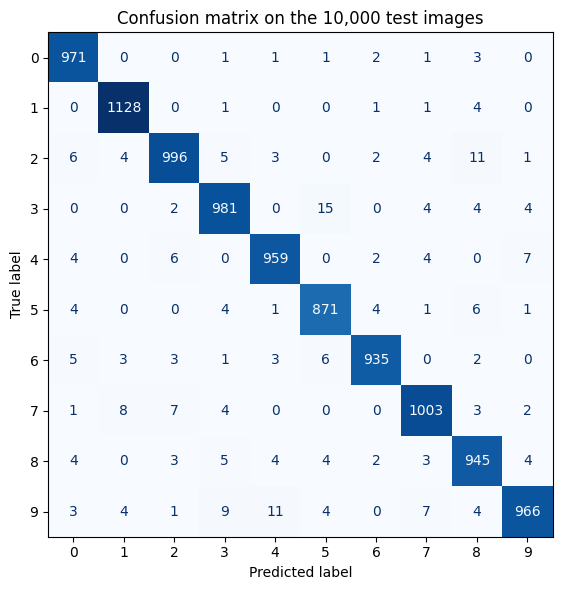

most common mistakes (count, true, predicted): [(np.int64(15), 3, 5), (np.int64(11), 9, 4), (np.int64(11), 2, 8), (np.int64(9), 9, 3), (np.int64(8), 7, 1)]


In [8]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix on the 10,000 test images")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(10) for j in range(10) if off[i, j]], reverse=True)[:5]
print("most common mistakes (count, true, predicted):", pairs)

**Some mistakes.** Test images the network got wrong, with the true label and the prediction.

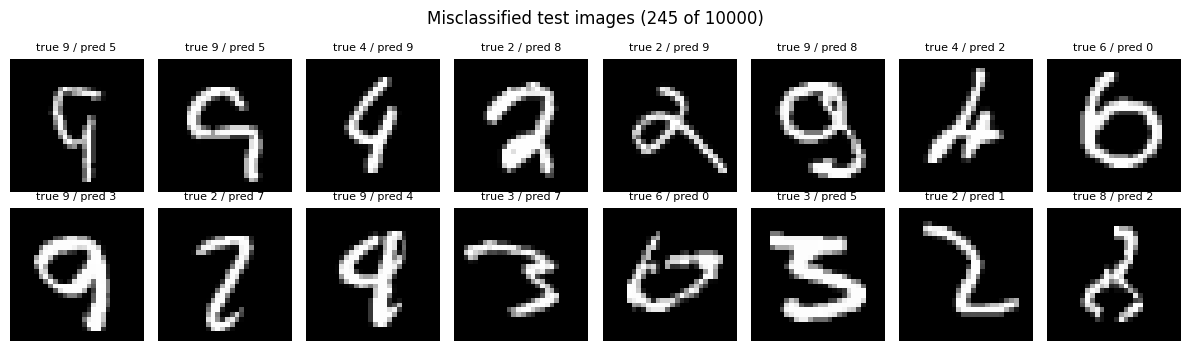

In [9]:
wrong = np.where(y_pred != y_test)[0]
fig, axes = plt.subplots(2, 8, figsize=(12, 3.6))
for ax, i in zip(axes.ravel(), wrong[:16]):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray"); ax.set_title(f"true {y_test[i]} / pred {y_pred[i]}", fontsize=8); ax.axis("off")
plt.suptitle(f"Misclassified test images ({len(wrong)} of {len(y_test)})")
plt.tight_layout(); plt.savefig(FIG / "mistakes.png", dpi=150); plt.show()

In [10]:
per_class = {int(k): float(v) for k, v in zip(range(10), cm.diagonal() / cm.sum(axis=1))}
Path("results.json").write_text(json.dumps({
    "train_acc": train_acc, "test_acc": test_acc, "train_loss": train_loss, "test_loss": test_loss,
    "best_val": mlp.best_validation_score_, "epochs": mlp.n_iter_, "train_time": train_time, "n_params": n_params,
    "loss_curve": mlp.loss_curve_, "val_curve": mlp.validation_scores_, "n_wrong": int(len(wrong)),
    "top_mistakes": [[int(c), int(t), int(p)] for c, t, p in pairs], "per_class_recall": per_class,
    "report": report, "sklearn": sklearn.__version__}, indent=1))
print("saved results.json")

saved results.json
